In [52]:
import duckdb
import pandas as pd 
from sklearn.metrics import mean_absolute_error
con = duckdb.connect("../data/power.duckdb", read_only=True)
con.sql("SET Timezone = 'UTC'")
df = con.sql("Select * FROM features ORDER BY ts_utc").df()
con.close()

df.shape

(70801, 17)

In [53]:
train = df[df["year"].between(2019,2023)]
valid = df[df["year"] == 2024]
test = df[df["year"] == 2025]
print("train:", len(train), "hours")
print("valid:", len(valid), "hours")
print("test:", len(test), "hours")

train: 43824 hours
valid: 8784 hours
test: 8760 hours


In [54]:
def evaluate(name, actual, predicted, threshold=0):
    """Scoring one models predicition - avg errir and negative hours that are caught"""
    actual_neg = actual < 0
    predicted_neg = predicted < threshold 
    caught = (actual_neg & predicted_neg).sum()
    false_alarms =(~actual_neg & predicted_neg).sum()
    return {
        "model": name,
        "mae_eur_mwh": round(mean_absolute_error(actual, predicted), 1),
        "negative_hours": int(actual_neg.sum()),
        "caught_pct": round(100 * caught / actual_neg.sum(), 1),
        "false_alarms_pct": round(100 * false_alarms / max(predicted_neg.sum(), 1), 1),
        
    }

What it measures:

- mae_eur_mwh: the average error. If the real prices were 50, 80, 100 and the guesses 60, 70, 100, the errors are 10, 10 and 0, so MAE = 6.7 €/MWh. Lower is better.
- caught_pct: of the hours that really were negative, how many did the model also predict as negative? ( call this recall.)
- false_alarm_pct: of the hours the model said would be negative, how many weren’t? (This is 100% minus precision.)
- & means “and”, ~ means “not”. So ~actual_neg & predicted_neg = “not actually negative, but predicted negative” = a false alarm.
- max(predicted_neg.sum(), 1) avoids dividing by zero if a model never predicts a negative hour.

In [55]:
results = pd.DataFrame([
    evaluate("same as yesterday", valid["price_euro_mwh"], valid["price_lag_24h"]),
    evaluate("same as last week", valid["price_euro_mwh"], valid["price_lag_168h"]),
])
results

,model,mae_eur_mwh,negative_hours,caught_pct,false_alarms_pct
0,same as yesterday,27.8,457,36.1,64.0
1,same as last week,32.8,457,33.5,69.2


In [56]:
check = valid.assign(
    error_yesterday=(valid["price_euro_mwh"] - valid["price_lag_24h"]).abs(),
    error_last_week=(valid["price_euro_mwh"] - valid["price_lag_168h"]).abs(),
)
check.groupby("weekday")[["error_yesterday", "error_last_week"]].mean().round(1)

,error_yesterday,error_last_week
weekday,,
1,41.1,28.6
2,24.2,30.7
3,25.9,39.0
4,25.9,38.8
5,26.2,32.3
6,27.6,28.0
7,23.7,32.3


### Baselines: two simple guessing rules (validation year 2024)

**What a baseline is:** a very simple rule that just copies an old price.
The real model must beat these rules, otherwise it's useless.

- **"Same as yesterday"** (`price_lag_24h`): to guess Tuesday 14:00,
  copy Monday 14:00.
- **"Same as last week"** (`price_lag_168h`): to guess Tuesday 14:00,
  copy last Tuesday 14:00 (7 days = 168 hours earlier).

**How we score them:**
- **MAE** (mean absolute error): how far off the guess is, on average,
  in €/MWh. Lower is better.
- **Caught %**: of the hours that really were negative, how many the rule
  also predicted as negative. Higher is better.
- **False alarm %**: of the hours the rule *said* would be negative, how
  many were not. Lower is better.

**Results for 2024:**

| Rule | MAE | Caught | False alarms |
| --- | --- | --- | --- |
| Same as yesterday | 27.8 €/MWh | 36% | 64% |
| Same as last week | 32.8 €/MWh | 34% | 69% |

**Findings:**
- "Same as yesterday" is better overall. Yesterday is only one day away,
  so the weather is usually similar (sunny or windy spells last a few days).
- **Exception: Mondays.** "Yesterday" copies Sunday, a cheap weekend day,
  so its guess for Monday (a working day) is far too low: error 41.1 €/MWh.
  "Last week" copies last Monday instead and does much better: 28.6 €/MWh.
- Both rules are weak at negative hours: they catch only about 1 in 3,
  and about 2 out of 3 of their "negative" guesses are wrong.
- The model will see both old prices **and** the weekday, so it can learn
  when to trust which one, e.g. "on Mondays, use last week".

In [57]:
FEATURES = [
    "hour","weekday","month","is_weekend","is_holiday","price_lag_24h","price_lag_48h","price_lag_168h","price_avg_7d",
    "radiation","wind_speed","temperature",
]

TARGET = "price_euro_mwh"

In [58]:
import lightgbm as lgb
model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    verbose=-1,
)
model.fit(train[FEATURES], train[TARGET])

,learning_rate,0.05
,n_estimators,500
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [59]:
valid_pred = model.predict(valid[FEATURES])

results = pd.concat([
    results,
    pd.DataFrame([evaluate("LightGBM", valid[TARGET], valid_pred)]),
], ignore_index=True)

results

,model,mae_eur_mwh,negative_hours,caught_pct,false_alarms_pct
0,same as yesterday,27.8,457,36.1,64.0
1,same as last week,32.8,457,33.5,69.2
2,LightGBM,19.3,457,28.4,9.7


In [60]:
gain = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index = FEATURES,
)
(100 * gain / gain.sum()).round(1).sort_values(ascending=False)

price_lag_24h     79.6
price_lag_168h     5.3
wind_speed         5.1
weekday            2.5
price_avg_7d       2.5
price_lag_48h      2.1
temperature        0.8
radiation          0.8
hour               0.6
month              0.5
is_holiday         0.2
is_weekend         0.0
dtype: float64

### LightGBM (trained on 2019–2023, scored on 2024)

**Result:**

| Model | MAE | Caught | False alarms |
| --- | --- | --- | --- |
| Same as yesterday | 27.8 €/MWh | 36% | 64% |
| LightGBM | 19.3 €/MWh | 28% | 10% |

- Average error 31% lower than the best simple rule (19.3 vs 27.8 €/MWh).
- A careful model: when it predicts a negative hour, it is right 9 times
  out of 10. But it misses about 7 in 10 negative hours, because it was
  trained to keep the average error low and negative hours are rare (~5%).

**Most important clues (share of improvement):**
- Yesterday's price at the same hour: 80%.
- Last week's price: 5%. Wind speed: 5%.
- Sun (radiation) under 1%: yesterday's price already contains most of the
  sun pattern, while wind changes more from day to day.
- Note: importance shows what the model used, not what causes prices.

In [61]:
actual_neg = valid[TARGET] < 0
rows = []
for threshold in[0, 10, 20, 30, 40]:
    flagged = valid_pred < threshold 
    caught = (actual_neg & flagged).sum()
    false_alarms = (~actual_neg & flagged).sum()
    rows.append({
        "threshold_eur_mwh": threshold,
        "hours_flagged": int(flagged.sum()),
        "caught_pct": round(100 * caught / actual_neg.sum(), 1),
        "false_alarm_pct": round(100 * false_alarms / max(flagged.sum(), 1), 1),
    })
pd.DataFrame(rows)

,threshold_eur_mwh,hours_flagged,caught_pct,false_alarm_pct
0,0,144,28.4,9.7
1,10,264,42.2,26.9
2,20,429,60.8,35.2
3,30,676,71.8,51.5
4,40,1036,81.8,63.9


### Catching more negative hours: choosing a threshold
Instead of "predicted price below 0", we warn when the predicted price is
below a threshold. Higher threshold = more negative hours caught, but more
false alarms.

| Threshold | Hours warned | Caught | False alarms |
| --- | --- | --- | --- |
| 0 €/MWh | 144 | 28% | 10% |
| 20 €/MWh | 429 | 61% | 35% |
| 40 €/MWh | 1,036 | 82% | 64% |

- At 20 €/MWh, LightGBM beats "same as yesterday" on both measures
  (61% vs 36% caught, 35% vs 64% false alarms).
- Chosen threshold: 20 €/MWh. For charging, a false alarm is usually
  still a cheap hour, while a miss loses the cheapest power of the day.
  - The 151 false alarms at 20 €/MWh were still very cheap hours: median real
  price 2.24 €/MWh, 75% under 13 €/MWh (2024 average: __ €/MWh).
  For charging, these "mistakes" were nearly as good as hits.

In [62]:
flagged_20 = valid_pred < 20
false_alarm_prices = valid.loc[flagged_20 & ~actual_neg, TARGET]
false_alarm_prices.describe()

count    151.000000
mean      10.536755
std       16.414850
min        0.000000
25%        0.055000
50%        2.240000
75%       12.930000
max       70.470000
Name: price_euro_mwh, dtype: float64

In [63]:
valid[TARGET].mean()

np.float64(78.51203324225865)

In [64]:
tuning = []
for num_leaves in [15, 31, 63]:
    for min_child_samples in [20, 100, 300]:
        candidate = lgb.LGBMRegressor(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=num_leaves,
            min_child_samples=min_child_samples,
            random_state=42,
            verbose=-1,
        )
        candidate.fit(train[FEATURES], train[TARGET])
        mae = mean_absolute_error(valid[TARGET], candidate.predict(valid[FEATURES]))
        tuning.append({
            "num_leaves": num_leaves,
            "min_child_samples": min_child_samples,
            "mae_eur_mwh": round(mae, 2),
        })

tuning = pd.DataFrame(tuning).sort_values("mae_eur_mwh")
tuning

,num_leaves,min_child_samples,mae_eur_mwh
6,63,20,19.10
7,63,100,19.14
1,15,100,19.24
3,31,20,19.28
5,31,300,19.28
2,15,300,19.30
0,15,20,19.32
4,31,100,19.32
8,63,300,19.33


In [65]:
best = tuning.iloc[0]
best_params = {
    "num_leaves": int(best["num_leaves"]),
    "min_child_samples": int(best["min_child_samples"]),
}
best_params

{'num_leaves': 63, 'min_child_samples': 20}

In [66]:
train_full = df[df["year"].between(2019, 2024)]

final_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    verbose=-1,
    **best_params,
)
final_model.fit(train_full[FEATURES], train_full[TARGET])
test_pred = final_model.predict(test[FEATURES])

final_results = pd.DataFrame([
    evaluate("Same as yesterday", test[TARGET], test["price_lag_24h"]),
    evaluate("Same as last week", test[TARGET], test["price_lag_168h"]),
    evaluate("LightGBM", test[TARGET], test_pred),
    evaluate("LightGBM, warn below 20", test[TARGET], test_pred, threshold=20),
])
final_results

,model,mae_eur_mwh,negative_hours,caught_pct,false_alarms_pct
0,Same as yesterday,26.0,573,54.3,45.7
1,Same as last week,32.8,573,43.6,56.4
2,LightGBM,19.8,573,37.3,9.7
3,"LightGBM, warn below 20",19.8,573,62.7,26.3


### Final test: 2025 (never used before)
Final model: LightGBM with num_leaves=63, min_child_samples=20, trained on
2019–2024. Tuning changed the 2024 MAE by only 0.2 €/MWh, so the defaults
were already close to optimal.

| Model | MAE | Caught | False alarms |
| --- | --- | --- | --- |
| Same as yesterday | 26.0 €/MWh | 54% | 46% |
| LightGBM | 19.8 €/MWh | 37% | 10% |
| LightGBM, warn below 20 | 19.8 €/MWh | 63% | 26% |

- Stable: MAE 19.3 on 2024 and 19.8 on 2025, so the model learned real
  patterns rather than memorising its training years.
- 24% lower error than the best simple rule (19.8 vs 26.0 €/MWh).
- With a warning threshold of 20 €/MWh it catches more negative hours than
  "same as yesterday" (63% vs 54%) with far fewer false alarms (26% vs 46%).
- "Same as yesterday" did better in 2025 than in 2024 (54% vs 36% caught):
  negative hours increasingly come in runs (sunny weekends, sunny weeks).

- Error Analysis 
The idea: one average (MAE 19.8) hides where the model is good and where it struggles. Now we slice the errors by groups, exactly like you did with the baselines and weekdays. The questions:

- Did the model fix the Monday problem?
- Which hours are hardest?
- Holidays, which we know are special.
- The 10 worst days: what happened then?
- The weather shortcut: how much does using the actual weather flatter the model?

In [67]:
errors = test.assign(
    predicted=test_pred,
    error_model=(test_pred - test[TARGET]).abs(),
    error_yesterday=(test["price_lag_24h"] - test[TARGET]).abs(),
)
errors[["ts_local", TARGET, "predicted", "error_model", "error_yesterday"]].head()

,ts_local,price_euro_mwh,predicted,error_model,error_yesterday
54817,2025-01-01 00:00:00,2.16,21.243574,19.083574,48.33
54818,2025-01-01 01:00:00,1.60,19.413682,17.813682,44.30
54819,2025-01-01 02:00:00,0.00,12.944755,12.944755,56.43
54820,2025-01-01 03:00:00,-0.01,6.673017,6.683017,57.07
54821,2025-01-01 04:00:00,-0.01,11.112919,11.122919,63.93


In [68]:
errors.groupby("weekday")[["error_model","error_yesterday"]].mean().round(1) ##question 1 the monday part

,error_model,error_yesterday
weekday,,
1,23.0,40.3
2,21.5,23.6
3,20.2,24.6
4,20.2,24.8
5,19.1,21.3
6,17.6,25.9
7,16.9,21.2


<Axes: title={'center': 'Average error by hour of the day, 2025 (Euro/Mwh)'}, xlabel='hour'>

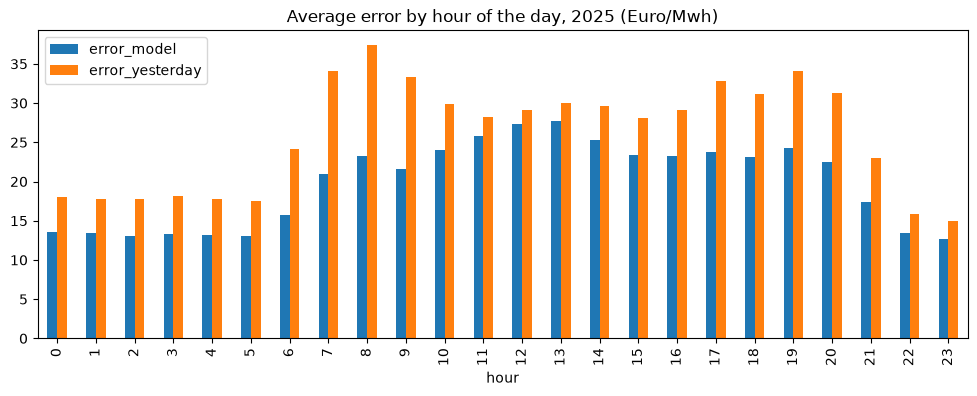

In [69]:
by_hour = errors.groupby("hour")[["error_model","error_yesterday"]].mean()
by_hour.plot(kind="bar", figsize=(12,4),
            title="Average error by hour of the day, 2025 (Euro/Mwh)")

### Error analysis (test year 2025)

**By weekday:** the Monday problem is largely fixed. Model error on Mondays
is 23.0 €/MWh vs 40.3 for "same as yesterday", close to other days
(16.9–21.5). Saturdays also improved a lot (17.6 vs 25.9).

**By hour:**
- Hardest: midday, 11:00–14:00 (about 26–28 €/MWh). Easiest: night,
  0:00–5:00 (about 13 €/MWh).
- Biggest improvement over "yesterday": morning (7:00–9:00) and evening
  (17:00–20:00), where weekday and weekend patterns differ.
- Smallest improvement: midday (about 27–28 vs 29–30). These are the solar
  hours where negative prices happen.
- Likely reason: the sun clue is crude (average sunshine at 6 places, no
  information on how much solar capacity exists).
- Next step for a future version: use actual or forecast solar generation
  (e.g. from SMARD) instead of raw sunshine.

  Next is Holidays and the worst days

In [70]:
errors.groupby("is_holiday")[["error_model", "error_yesterday"]].mean().round(1)

,error_model,error_yesterday
is_holiday,,
False,19.8,25.8
True,19.6,31.6


False is the normal days and True is holidays


In [71]:
errors["date"] =errors ["ts_local"].dt.date
worst_days = (
    errors.groupby("date")
    .agg(
        error_model=("error_model", "mean"),
        avg_price=(TARGET, "mean"),
        min_price=(TARGET, "min"),
        max_price=(TARGET, "max"),
        is_holiday=("is_holiday", "max"),
        weekday=("weekday", "first"),
        avg_wind=("wind_speed","mean"),
        price_yesterday=("price_lag_24h", "mean"),
    )
    .round(1)
    .sort_values("error_model", ascending=False)
    .head(10)
)
worst_days

,error_model,avg_price,min_price,max_price,is_holiday,weekday,avg_wind,price_yesterday
date,,,,,,,,
2025-01-15,79.7,222.2,107.7,378.0,False,3,17.1,126.8
2025-11-25,74.9,220.5,96.1,373.3,False,2,15.9,132.4
2025-01-20,72.5,231.4,114.4,583.4,False,1,14.4,128.7
2025-01-27,71.6,60.2,10.1,118.7,False,1,33.3,101.5
2025-01-21,69.1,168.5,113.5,301.2,False,2,15.8,231.4
2025-02-20,62.4,94.9,82.2,128.0,False,4,24.9,110.8
2025-01-24,60.4,78.9,40.6,116.2,False,5,34.1,103.9
2025-02-19,60.3,110.8,81.5,166.4,False,3,22.3,132.5
2025-11-28,55.8,85.0,47.9,104.7,False,5,27.9,91.2


In [72]:
errors["wind_speed"].mean()

np.float64(21.265631659056318)

### The 10 worst days of 2025
All in winter (Jan, Feb, late Nov), all weekdays, none holidays.
The common pattern: a sudden change from yesterday's price, mostly
driven by wind (2025 average wind: 21.3 km/h).

- **Price jumps on calm days:** e.g. 15 Jan: wind 17.1 km/h, average price
  rose from 127 to 222 €/MWh. Likely the start of a "Dunkelflaute"
  (cold, dark, windless).
- **Price drops on stormy days:** e.g. 27 Jan: wind 33.3 km/h, price fell
  from 102 to 60 €/MWh.
- **Days after a spike:** e.g. 16 Jan: yesterday 222, today 148 €/MWh.
  The model leans on yesterday's price (80% of its importance), so it
  guesses too high when prices fall back.
- Not everything is explained: on 28 Nov the price barely changed, but the
  error was still large.
- Note: errors are in €/MWh, so expensive days naturally produce bigger
  errors.
- Next step for a future version: features that describe change, e.g.
  "wind today minus wind yesterday".

In [73]:
NO_WEATHER = [f for f in FEATURES if f not in ["radiation", "wind_speed", "temperature"]]

model_no_weather = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    verbose=-1,
    **best_params,
)
model_no_weather.fit(train_full[NO_WEATHER], train_full[TARGET])
pred_no_weather = model_no_weather.predict(test[NO_WEATHER])

weather_check = pd.DataFrame([
    evaluate("Same as yesterday", test[TARGET], test["price_lag_24h"]),
    evaluate("LightGBM, no weather", test[TARGET], pred_no_weather, threshold=20),
    evaluate("LightGBM, actual weather", test[TARGET], test_pred, threshold=20),
])
weather_check

,model,mae_eur_mwh,negative_hours,caught_pct,false_alarms_pct
0,Same as yesterday,26.0,573,54.3,45.7
1,"LightGBM, no weather",23.8,573,56.0,31.4
2,"LightGBM, actual weather",19.8,573,62.7,26.3


### How much does the weather shortcut flatter the model?
The model uses the actual weather, but a real forecast at 10:00 would only
have a weather forecast. Testing the two extremes on 2025:

| Model | MAE | Caught | False alarms |
| --- | --- | --- | --- |
| Same as yesterday | 26.0 €/MWh | 54% | 46% |
| LightGBM, no weather | 23.8 €/MWh | 56% | 31% |
| LightGBM, actual weather | 19.8 €/MWh | 63% | 26% |

- About two-thirds of the improvement over "yesterday" comes from the
  weather (4.0 of 6.2 €/MWh), although the importance table gave weather
  only ~7%. Removing clues and retraining shows their real value better
  than importance scores.
- A real system with weather forecasts would land between the two:
  8% to 24% better than "same as yesterday".

In [74]:
forecast = pd.read_parquet("../data/raw/weather_forecast_2025.parquet")
forecast_de = forecast.groupby("ts_utc").mean(numeric_only=True)


def with_forecast_weather(data, days_ahead):
    """Replace the actual weather in `data` with what was forecast days_ahead before."""
    weather = pd.DataFrame({
        # radiation: same one-hour shift as LEAD(...) in sql/02_features.sql
        "radiation": forecast_de[f"shortwave_radiation_previous_day{days_ahead}"].shift(-1),
        "wind_speed": forecast_de[f"wind_speed_100m_previous_day{days_ahead}"],
        "temperature": forecast_de[f"temperature_2m_previous_day{days_ahead}"],
    })
    return (
        data.drop(columns=["radiation", "wind_speed", "temperature"])
        .merge(weather, left_on="ts_utc", right_index=True, how="left")
    )


test_fc1 = with_forecast_weather(test, days_ahead=1)
test_fc2 = with_forecast_weather(test, days_ahead=2)

test_fc1[["radiation", "wind_speed", "temperature"]].isna().sum()

radiation      1
wind_speed     1
temperature    1
dtype: int64

In [75]:
pred_fc1 = final_model.predict(test_fc1[FEATURES])
pred_fc2 = final_model.predict(test_fc2[FEATURES])

forecast_check = pd.DataFrame([
    evaluate("Same as yesterday", test[TARGET], test["price_lag_24h"]),
    evaluate("LightGBM, no weather", test[TARGET], pred_no_weather, threshold=20),
    evaluate("LightGBM, forecast 2 days ahead", test[TARGET], pred_fc2, threshold=20),
    evaluate("LightGBM, forecast 1 day ahead", test[TARGET], pred_fc1, threshold=20),
    evaluate("LightGBM, actual weather", test[TARGET], test_pred, threshold=20),
])
forecast_check

,model,mae_eur_mwh,negative_hours,caught_pct,false_alarms_pct
0,Same as yesterday,26.0,573,54.3,45.7
1,"LightGBM, no weather",23.8,573,56.0,31.4
2,"LightGBM, forecast 2 days ahead",19.6,573,63.4,29.1
3,"LightGBM, forecast 1 day ahead",20.0,573,62.5,25.7
4,"LightGBM, actual weather",19.8,573,62.7,26.3


In [76]:
diff = (test_fc2["wind_speed"].values - test["wind_speed"].values)
print("Average wind:", round(test["wind_speed"].mean(), 1), "km/h")
print("Average forecast error (2 days ahead):", round(abs(diff[~pd.isna(diff)]).mean(), 1), "km/h")

Average wind: 21.3 km/h
Average forecast error (2 days ahead): 2.3 km/h


### Test with real weather forecasts (Open-Meteo Previous Runs API)
The same final model, scored on 2025 with the weather that was forecast
1 or 2 days in advance instead of the actual weather.

| Model | MAE | Caught | False alarms |
| --- | --- | --- | --- |
| Same as yesterday | 26.0 €/MWh | 54% | 46% |
| LightGBM, no weather | 23.8 €/MWh | 56% | 31% |
| LightGBM, forecast 2 days ahead | 19.6 €/MWh | 63% | 29% |
| LightGBM, forecast 1 day ahead | 20.0 €/MWh | 63% | 26% |
| LightGBM, actual weather | 19.8 €/MWh | 63% | 26% |

- Using real forecasts made almost no difference (19.6–20.0 vs 19.8 €/MWh),
  so the actual-weather shortcut did not flatter the results.
- The fair version (2-day-old forecasts, always available at 10:00) is
  about 25% better than "same as yesterday" and catches 63% of negative
  hours (vs 54%) with fewer false alarms (29% vs 46%).
- Differences of 0.2–0.4 €/MWh between the three are within noise.
- A check showed- the 2-day-old wind forecast was off by 2.3 km/h on average
  (actual average wind: 21.3 km/h), so the forecasts are genuinely
  different from the actual weather, but accurate.

In [77]:
from pathlib import Path

out_dir = Path("../data/reports")
out_dir.mkdir(parents=True, exist_ok=True)

forecast_2025 = pd.DataFrame({
    "ts_local": test["ts_local"].values,
    "actual_price": test[TARGET].values,
    "predicted_price": pred_fc2,
    "same_as_yesterday": test["price_lag_24h"].values,
})
forecast_2025["warning"] = forecast_2025["predicted_price"] < 20

forecast_2025.to_csv(out_dir / "forecast_2025.csv", index=False)
forecast_check.to_csv(out_dir / "model_comparison.csv", index=False)
print("Saved", len(forecast_2025), "forecast rows and", len(forecast_check), "model rows")

Saved 8760 forecast rows and 5 model rows


In [78]:
con.close()